<a href="https://colab.research.google.com/github/D2718281828nis/ML-Reservoir_Computing/blob/master/notebooks/00_ffn_vs_reservoir_computing.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# 00 · Feed-forward networks vs reservoir computing

**Companion to the interactive page** [Reservoir Computing Explainer](https://d2718281828nis.github.io/ML-Reservoir_Computing/) ([на русском](https://d2718281828nis.github.io/ML-Reservoir_Computing/ru/)).
Every experiment on the page is repeated here in plain numpy, so you can read, change and rerun each step.

| Part | Question | Section here |
|---|---|---|
| 2 | What does a feed-forward network (FFN) need to forecast? | §2 |
| 3 | What does a random, untrained reservoir do with its input? | §3 |
| 4 | Is it the *training* or the *recurrence* that makes reservoirs fast? | §4 |
| 5 | How do the models compare on real data, with honest baselines? | §5 |
| 6 | Can delays and polynomials (NG-RC) replace the reservoir? | §6 |

Dependencies: `numpy`, `pandas`, `matplotlib`. The whole notebook runs in about a minute on a laptop CPU.
The random draws differ from the page's JavaScript, so individual numbers differ a little; the conclusions don't.

In [1]:
import time
from itertools import combinations_with_replacement
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

plt.rcParams.update({"figure.figsize": (11, 3.2), "axes.grid": True, "grid.alpha": 0.3,
                     "axes.spines.top": False, "axes.spines.right": False, "figure.dpi": 100})
COL = {"truth": "#1c1b19", "esn": "#2a78d6", "ffn": "#eb6834", "ngrc": "#1baf7a", "elm": "#eda100", "base": "#76736b"}

# the repository's data folder (works from notebooks/ and from the repository root; on Colab, files are fetched from GitHub)
RAW = "https://raw.githubusercontent.com/D2718281828nis/ML-Reservoir_Computing/master/dataset/"
DATA = next((p for p in [Path("../dataset"), Path("dataset")] if p.exists()), None)
data_path = lambda name: DATA / name if DATA else RAW + name

## 1 · Data and shared tools

**Mackey–Glass** ($\tau = 17$) is the running example of parts 2–4: a delay equation whose value depends on itself 17 time units ago,
$\dot x = 0.2\,x(t-17)/(1 + x(t-17)^{10}) - 0.1\,x(t)$. It is integrated with RK4 at step 0.1 and sampled once per time unit.
**Lorenz-63** is the chaotic system of part 6. Both integrators are the same as the page's `js/data.js`.

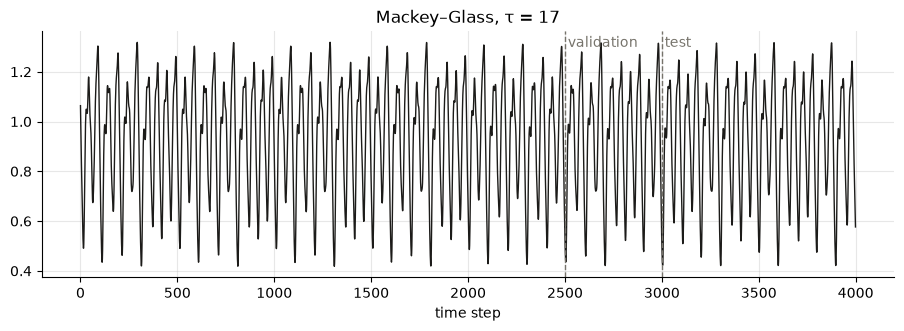

In [2]:
def mackey_glass(n, tau=17, beta=0.2, gamma=0.1, p=10, dt=0.1, sub=10, x0=1.2, discard=500):
    d = int(round(tau / dt))
    total = (n + discard) * sub
    hist = np.full(total + d + 1, x0)
    f = lambda x, xt: beta * xt / (1 + xt ** p) - gamma * x
    for i in range(d, d + total):
        x, xt0, xt1 = hist[i], hist[i - d], hist[i - d + 1]
        xth = 0.5 * (xt0 + xt1)                      # delayed value at the half step
        k1 = f(x, xt0); k2 = f(x + 0.5 * dt * k1, xth); k3 = f(x + 0.5 * dt * k2, xth); k4 = f(x + dt * k3, xt1)
        hist[i + 1] = x + dt / 6 * (k1 + 2 * k2 + 2 * k3 + k4)
    return hist[d + discard * sub::sub][:n]

def lorenz(n, dt=0.025, s=10.0, r=28.0, b=8 / 3, x0=(17.67715816276679, 12.931379185960404, 43.91404334248268)):
    f = lambda v: np.array([s * (v[1] - v[0]), v[0] * (r - v[2]) - v[1], v[0] * v[1] - b * v[2]])
    v, out = np.array(x0, float), np.zeros((n, 3))
    for i in range(n):
        out[i] = v
        k1 = f(v); k2 = f(v + dt / 2 * k1); k3 = f(v + dt / 2 * k2); k4 = f(v + dt * k3)
        v = v + dt / 6 * (k1 + 2 * k2 + 2 * k3 + k4)
    return out

mg = mackey_glass(4000)
TRAIN_END, VAL_END = 2500, 3000                      # train [0, 2500) · validation [2500, 3000) · test [3000, 4000)
mu, sd = mg[:TRAIN_END].mean(), mg[:TRAIN_END].std()
z = (mg - mu) / sd                                   # scaled with the training part only

fig, ax = plt.subplots()
ax.plot(mg, color=COL["truth"], lw=1)
for t, name in [(TRAIN_END, "validation"), (VAL_END, "test")]:
    ax.axvline(t, color=COL["base"], ls="--", lw=1); ax.text(t + 15, 1.3, name, color=COL["base"])
ax.set(title="Mackey–Glass, τ = 17", xlabel="time step"); plt.show()

In [3]:
def ridge(F, Y, lam):
    # argmin (1/n)‖F B − Y‖² + λ‖B‖²  — the readout of every reservoir-style model
    n, p = F.shape
    return np.linalg.solve(F.T @ F + lam * n * np.eye(p), F.T @ Y)

LAMBDAS = 10.0 ** np.arange(-12, -1)

def fit_readout(F, Y, train, val):
    # fit on train rows, choose λ by validation MSE
    best = None
    for lam in LAMBDAS:
        B = ridge(F[train], Y[train], lam)
        mse = np.mean((F[val] @ B - Y[val]) ** 2)
        if best is None or mse < best[2]:
            best = (B, lam, mse)
    return best[0], best[1]

def nrmse(y, yhat, axis=0):
    return np.sqrt(np.mean((y - yhat) ** 2, axis=axis)) / np.std(y, axis=axis)

def windows(z, L, n):
    # row t = [z(t), z(t−1), …, z(t−L+1)]; rows before the first full window are zeros (never used)
    X = np.zeros((n, L))
    for j in range(L):
        X[j:, j] = z[: n - j]
    X[: L - 1] = 0
    return X

def task(z, H, train_end=TRAIN_END, val_end=VAL_END):
    # forecast origins t (same for every model), target z(t+H); 50 steps of reservoir washout at the start
    n = len(z) - H
    rows = lambda a, b: np.arange(a, b)
    return dict(n=n, Y=z[H:H + n], train=rows(50, train_end - H), val=rows(train_end, val_end - H), test=rows(val_end, n))

## 2 · The feed-forward network: a function of a window

A multilayer perceptron gets the last $L$ values and predicts the value $H = 20$ steps ahead. Every weight is trained with backpropagation and Adam;
the weights of the epoch with the lowest validation error are kept (early stopping).

In [4]:
class MLP:
    # tanh hidden layers, linear output, PyTorch's default initialisation, Adam
    def __init__(self, sizes, seed=1):
        r = np.random.default_rng(seed)
        self.W = [r.uniform(-1, 1, (o, i)) / np.sqrt(i) for i, o in zip(sizes[:-1], sizes[1:])]
        self.b = [r.uniform(-1, 1, o) / np.sqrt(i) for i, o in zip(sizes[:-1], sizes[1:])]
        self.m = [np.zeros_like(p) for p in self.W + self.b]
        self.v = [np.zeros_like(p) for p in self.W + self.b]
        self.t = 0

    @property
    def n_params(self):
        return sum(p.size for p in self.W + self.b)

    def forward(self, X):
        A = [X]
        for k, (W, b) in enumerate(zip(self.W, self.b)):
            a = A[-1] @ W.T + b
            A.append(np.tanh(a) if k < len(self.W) - 1 else a)
        return A

    def predict(self, X):
        return self.forward(X)[-1]

    def step(self, X, Y, lr):
        A = self.forward(X)
        d = 2 * (A[-1] - Y) / Y.size                  # gradient of the mean squared error
        gW, gb = [], []
        for k in range(len(self.W) - 1, -1, -1):      # backpropagation
            gW.insert(0, d.T @ A[k]); gb.insert(0, d.sum(0))
            if k:
                d = (d @ self.W[k]) * (1 - A[k] ** 2)
        self.t += 1
        for i, (p, g) in enumerate(zip(self.W + self.b, gW + gb)):   # Adam
            self.m[i] = 0.9 * self.m[i] + 0.1 * g
            self.v[i] = 0.999 * self.v[i] + 0.001 * g * g
            p -= lr * (self.m[i] / (1 - 0.9 ** self.t)) / (np.sqrt(self.v[i] / (1 - 0.999 ** self.t)) + 1e-8)

def train_mlp(X, Y, train, val, hidden=(32, 32), epochs=150, lr=2e-3, batch=32, seed=1, history=False):
    Y2 = Y.reshape(len(Y), -1)
    net = MLP([X.shape[1], *hidden, Y2.shape[1]], seed)
    r = np.random.default_rng(seed + 99)
    best, hist, t0 = (np.inf, None, 0), [], time.perf_counter()
    for ep in range(1, epochs + 1):
        order = r.permutation(train)
        for i in range(0, len(order), batch):
            idx = order[i:i + batch]
            net.step(X[idx], Y2[idx], lr)
        val_mse = np.mean((net.predict(X[val]) - Y2[val]) ** 2)
        if val_mse < best[0]:
            best = (val_mse, ([w.copy() for w in net.W], [b.copy() for b in net.b]), ep)
        if history:
            hist.append(np.sqrt(val_mse))
    net.W, net.b = best[1]
    return net, dict(time=time.perf_counter() - t0, best_epoch=best[2], history=hist)

H = 20
T20 = task(z, H)
rows = []
for L in [3, 10, 20]:
    X = windows(z, L, T20["n"])
    net, info = train_mlp(X, T20["Y"], T20["train"], T20["val"], seed=2, history=True)
    err = nrmse(T20["Y"][T20["test"]], net.predict(X[T20["test"]])[:, 0])
    rows.append(dict(window_L=L, trained_weights=net.n_params, test_NRMSE=round(err, 4), best_epoch=info["best_epoch"], seconds=round(info["time"], 1)))
    if L == 20:
        curve, pred20 = info["history"], net.predict(X[T20["test"]])[:, 0]
pd.DataFrame(rows)

,window_L,trained_weights,test_NRMSE,best_epoch,seconds
0,3,1217,0.1833,145,0.6
1,10,1441,0.0166,137,0.6
2,20,1761,0.0083,142,0.7


The window is all the memory an FFN has: Mackey–Glass feeds back $x(t-17)$, and with $L = 3$ that value is simply not in the input.

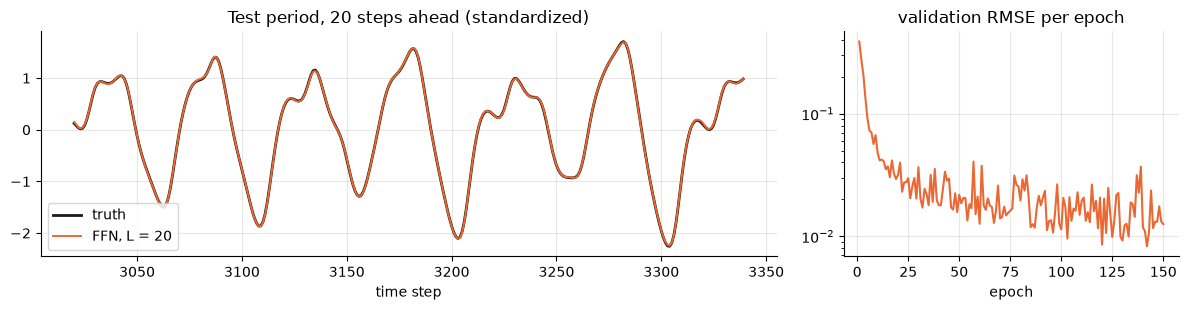

In [5]:
fig, (a1, a2) = plt.subplots(1, 2, figsize=(12, 3.2), gridspec_kw={"width_ratios": [2.2, 1]})
s = slice(0, 320)
a1.plot(T20["test"][s] + H, T20["Y"][T20["test"]][s], color=COL["truth"], lw=2, label="truth")
a1.plot(T20["test"][s] + H, pred20[s], color=COL["ffn"], lw=1.4, label="FFN, L = 20")
a1.set(title="Test period, 20 steps ahead (standardized)", xlabel="time step"); a1.legend()
a2.semilogy(range(1, len(curve) + 1), curve, color=COL["ffn"]); a2.set(title="validation RMSE per epoch", xlabel="epoch")
plt.tight_layout(); plt.show()

## 3 · The reservoir: a random recurrent network nobody trains

$x(t) = (1-\alpha)\,x(t-1) + \alpha\tanh(W_\text{in} u(t) + W x(t-1) + b)$, readout $\hat y = W_\text{out}[1; u(t); x(t)]$.
Each neuron listens to 10 random others; $W$ is rescaled to the spectral radius $\rho$ (here with numpy's exact eigenvalues).

In [6]:
class ESN:
    def __init__(self, N=300, rho=0.9, leak=0.5, in_scale=0.5, bias=0.2, degree=10, n_in=1, seed=1):
        r = np.random.default_rng(seed)
        W = np.zeros((N, N))
        for i in range(N):
            W[i, r.choice(N, degree, replace=False)] = r.uniform(-1, 1, degree)
        self.W = W * rho / np.max(np.abs(np.linalg.eigvals(W)))
        self.Win = r.uniform(-1, 1, (N, n_in)) * in_scale
        self.b = r.uniform(-1, 1, N) * bias
        self.N, self.leak = N, leak

    def step(self, x, u):
        return (1 - self.leak) * x + self.leak * np.tanh(self.Win @ np.atleast_1d(u) + self.W @ x + self.b)

    def run(self, U, x0=None):
        U = U.reshape(len(U), -1)
        x = np.zeros(self.N) if x0 is None else x0.copy()
        X = np.zeros((len(U), self.N))
        for t, u in enumerate(U):
            x = self.step(x, u)
            X[t] = x
        return X

    def features(self, U, X):
        return np.hstack([np.ones((len(X), 1)), U.reshape(len(U), -1), X])

### 3.1 The echo state property

Two copies of the same reservoir, started from different random states, driven by the same input. If their distance falls to zero, the reservoir has
forgotten its initial state, and its state is a function of the input history alone. $\rho < 1$ is a rule of thumb, not the condition: a strong input can
restore the property at $\rho = 2$.

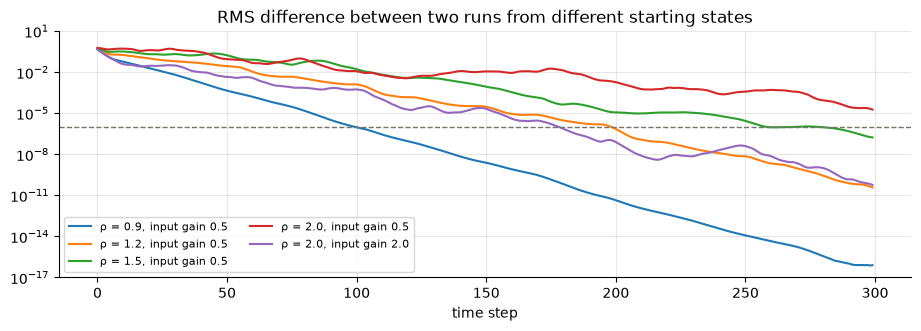

In [7]:
u = z[VAL_END:VAL_END + 300]
fig, ax = plt.subplots()
for rho, gain in [(0.9, 0.5), (1.2, 0.5), (1.5, 0.5), (2.0, 0.5), (2.0, 2.0)]:
    esn = ESN(100, rho, 0.5, gain, seed=1)
    r = np.random.default_rng(1)
    XA, XB = esn.run(u, r.uniform(-1, 1, 100)), esn.run(u, r.uniform(-1, 1, 100))
    ax.semilogy(np.sqrt(np.mean((XA - XB) ** 2, 1)) + 1e-17, label=f"ρ = {rho}, input gain {gain}")
ax.axhline(1e-6, color=COL["base"], ls="--", lw=1)
ax.set(title="RMS difference between two runs from different starting states", xlabel="time step", ylim=(1e-17, 10)); ax.legend(fontsize=8, ncol=2)
plt.show()

### 3.2 Memory capacity

Drive the reservoir with white noise and fit one linear readout per delay $k$ to recall $u(t-k)$. A window of $L$ values recalls delays $0 \dots L-1$
exactly and nothing beyond; the reservoir's recall fades. Memory capacity $\sum_k r^2(k)$ is at most $N$ (Jaeger, 2002).

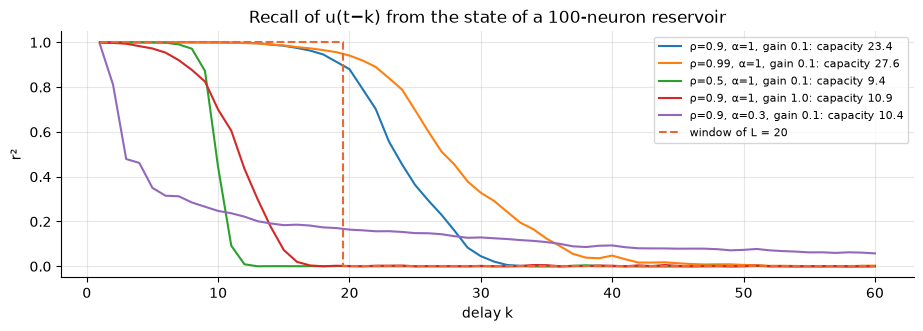

In [8]:
r = np.random.default_rng(5)
un = r.uniform(-1, 1, 2200)
K = 60
Yk = np.stack([np.concatenate([np.zeros(k), un[:-k]]) for k in range(1, K + 1)], 1)   # column k−1: u(t−k)
tr, te = np.arange(100, 1600), np.arange(1600, 2200)

fig, ax = plt.subplots()
for rho, leak, gain in [(0.9, 1, 0.1), (0.99, 1, 0.1), (0.5, 1, 0.1), (0.9, 1, 1.0), (0.9, 0.3, 0.1)]:
    esn = ESN(100, rho, leak, gain, bias=0, seed=3)
    F = esn.features(un, esn.run(un))
    P = F[te] @ ridge(F[tr], Yk[tr], 1e-7)
    r2 = np.array([np.corrcoef(P[:, k], Yk[te, k])[0, 1] ** 2 for k in range(K)])
    ax.plot(range(1, K + 1), r2, label=f"ρ={rho}, α={leak}, gain {gain}: capacity {r2.sum():.1f}")
ax.step(range(1, K + 1), [1.0 if k <= 19 else 0.0 for k in range(1, K + 1)], where="mid", color=COL["ffn"], ls="--", label="window of L = 20")
ax.set(title="Recall of u(t−k) from the state of a 100-neuron reservoir", xlabel="delay k", ylabel="r²"); ax.legend(fontsize=8)
plt.show()

## 4 · Head to head: is it the training or the recurrence?

Four models on the same task (Mackey–Glass, 20 steps ahead). Three are trained only at the readout, in one ridge solve each:

* **linear AR**: ridge on the window itself;
* **ELM** (extreme learning machine): the window through 300 fixed random tanh units;
* **ESN**: 300 reservoir neurons, no window at all.

The **FFN** trains every weight. The ELM differs from the FFN only in *what is trained*, and from the ESN only in *where the memory lives*.

In [9]:
def fit_linear(z, T, L):
    t0 = time.perf_counter()
    X = windows(z, L, T["n"]); F = np.hstack([np.ones((T["n"], 1)), X])
    B, lam = fit_readout(F, T["Y"], T["train"], T["val"])
    return nrmse(T["Y"][T["test"]], F[T["test"]] @ B), time.perf_counter() - t0, F.shape[1]

def fit_elm(z, T, L, M=300, seed=1):
    t0 = time.perf_counter()
    r = np.random.default_rng(seed)
    A, c = r.uniform(-1, 1, (M, L)) * 1.5 / np.sqrt(L), r.uniform(-0.5, 0.5, M)
    X = windows(z, L, T["n"]); F = np.hstack([np.ones((T["n"], 1)), X, np.tanh(X @ A.T + c)])
    B, lam = fit_readout(F, T["Y"], T["train"], T["val"])
    return nrmse(T["Y"][T["test"]], F[T["test"]] @ B), time.perf_counter() - t0, F.shape[1]

def fit_esn(z, T, seed=1, **cfg):
    t0 = time.perf_counter()
    esn = ESN(**{"N": 300, "rho": 1.0, "leak": 0.5, "in_scale": 0.5, "bias": 0.2, **cfg}, seed=seed)
    U = z[:T["n"]]; F = esn.features(U, esn.run(U))
    B, lam = fit_readout(F, T["Y"], T["train"], T["val"])
    return nrmse(T["Y"][T["test"]], F[T["test"]] @ B), time.perf_counter() - t0, F.shape[1]

def fit_ffn(z, T, L, seed=1):
    X = windows(z, L, T["n"])
    net, info = train_mlp(X, T["Y"], T["train"], T["val"], seed=seed)
    return nrmse(T["Y"][T["test"]], net.predict(X[T["test"]])[:, 0]), info["time"], net.n_params

rows = []
for L in [20, 3]:
    for seed in [1, 2, 3]:
        for name, fn in [("linear AR", lambda: fit_linear(z, T20, L)), ("ELM", lambda: fit_elm(z, T20, L, seed=seed)),
                         ("ESN", lambda: fit_esn(z, T20, seed=seed)), ("FFN", lambda: fit_ffn(z, T20, L, seed=seed))]:
            err, sec, k = fn()
            rows.append(dict(window_L=L if name != "ESN" else "none", model=name, seed=seed, test_NRMSE=err, seconds=sec, trained_weights=k))
race = pd.DataFrame(rows)
(race.groupby(["window_L", "model"], sort=False)
     .agg(test_NRMSE_median=("test_NRMSE", "median"), test_NRMSE_min=("test_NRMSE", "min"), test_NRMSE_max=("test_NRMSE", "max"),
          seconds=("seconds", "median"), trained_weights=("trained_weights", "first"))
     .round(5))

test_NRMSE_median  test_NRMSE_min  test_NRMSE_max  \
window_L model                                                          
20       linear AR            0.51835         0.51835         0.51835   
         ELM                  0.00057         0.00057         0.00070   
none     ESN                  0.00050         0.00038         0.00053   
20       FFN                  0.00828         0.00761         0.00835   
3        linear AR            0.59548         0.59548         0.59548   
         ELM                  0.13303         0.13278         0.13346   
         FFN                  0.18323         0.17956         0.18326   

                    seconds  trained_weights  
window_L model                                
20       linear AR  0.00074               21  
         ELM        0.01741              321  
none     ESN        0.05087              302  
20       FFN        0.66871             1761  
3        linear AR  0.00059                4  
         ELM        0.01415              304  
         FFN        0.60747             1217

What to read from the table:

* readout-only models (ELM, ESN) are as accurate as the FFN or better, after one linear solve;
* the ELM gets the FFN's exact input, so the speed comes from *the training*, not from recurrence;
* with $L = 3$ every window model collapses while the ESN, which has no window, is unaffected: the recurrence buys *memory*;
* linear features alone (linear AR) are not enough: the accuracy comes from the many nonlinear features.

## 5 · Forecasting real series, with honest baselines

The recipe: chronological train / validation / test; scaling with the training part only; washout; hyperparameters (λ, the FFN's epoch) chosen on
validation; persistence and seasonal-naive baselines; all horizons at once (one readout column, or one FFN output unit, per horizon).

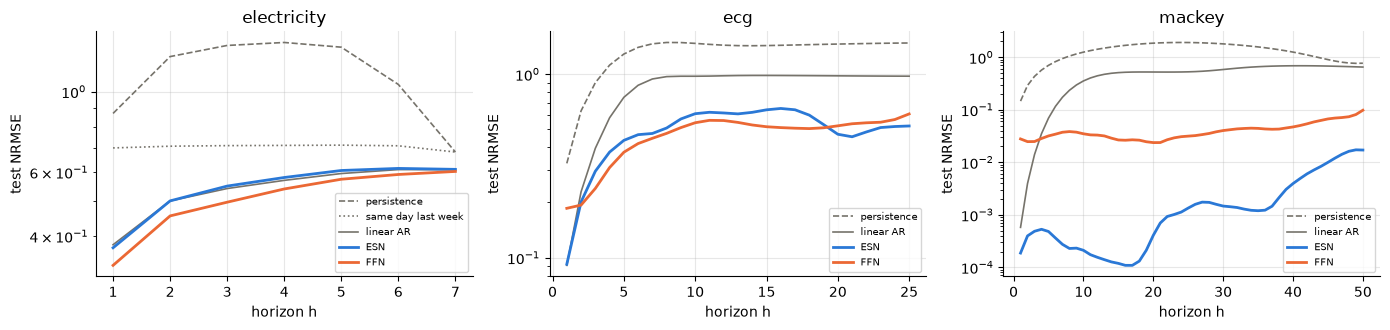

,dataset,model,h1,hH,seconds
0,electricity,persistence,0.870,0.682,0.000
1,electricity,same day last week,0.700,0.682,0.000
2,electricity,linear AR,0.379,0.610,0.001
3,electricity,ESN,0.372,0.611,0.021
4,electricity,FFN,0.332,0.603,0.390
5,ecg,persistence,0.327,1.478,0.000
6,ecg,linear AR,0.091,0.975,0.002
7,ecg,ESN,0.092,0.522,0.058
8,ecg,FFN,0.186,0.607,0.357
9,mackey,persistence,0.146,0.769,0.000


In [10]:
def load_electricity():
    df = pd.read_csv(data_path("spain_energy_market.csv"))
    d = df[df["name"] == "Demanda real"].copy()
    d["date"] = pd.to_datetime(d["datetime"]).dt.normalize()
    s = d.groupby("date")["value"].mean()
    s = s.reindex(pd.date_range(s.index.min(), s.index.max(), freq="D")).interpolate() / 1000   # GW
    return s.to_numpy(), int((s.index < "2017-01-01").sum()), int((s.index < "2018-01-01").sum())

def load_ecg():
    x = pd.read_csv(data_path("ecg_1d_timeseries_prediction.csv"), sep=";")["ecg_value"].to_numpy(float)
    x = x[: len(x) // 4 * 4].reshape(-1, 4).mean(1)                                            # 1 kHz → 250 Hz
    return x, round(len(x) * 0.6), round(len(x) * 0.8)

PRESETS = {
    "electricity": dict(load=load_electricity, H=7, period=7, L=28, hidden=(32,), epochs=300, lr=1e-3, esn=dict(N=200, rho=0.9, leak=1.0)),
    "ecg":         dict(load=load_ecg, H=25, period=0, L=50, hidden=(32,), epochs=100, lr=1e-3, esn=dict(N=300, rho=0.9, leak=0.3)),
    "mackey":      dict(load=lambda: (mg, TRAIN_END, VAL_END), H=50, period=0, L=20, hidden=(32,), epochs=120, lr=2e-3, esn=dict(N=300, rho=1.0, leak=0.5)),
}

def lab(name):
    p = PRESETS[name]
    x, tr_end, va_end = p["load"]()
    zz = (x - x[:tr_end].mean()) / x[:tr_end].std()
    H, n = p["H"], len(zz) - p["H"]
    Y = np.stack([zz[h:h + n] for h in range(1, H + 1)], 1)                       # row t: z(t+1 … t+H)
    rows = dict(train=np.arange(50, tr_end - H), val=np.arange(tr_end, va_end - H), test=np.arange(va_end, n))
    te, Yte, out = rows["test"], Y[rows["test"]], {}
    out["persistence"] = (nrmse(Yte, np.repeat(zz[te, None], H, 1)), 0.0)
    if p["period"]:
        P = np.stack([zz[te + h - p["period"] * int(np.ceil(h / p["period"]))] for h in range(1, H + 1)], 1)
        out["same day last week"] = (nrmse(Yte, P), 0.0)
    t0 = time.perf_counter(); Xw = windows(zz, p["L"], n); F = np.hstack([np.ones((n, 1)), Xw])
    B, _ = fit_readout(F, Y, rows["train"], rows["val"]); out["linear AR"] = (nrmse(Yte, F[te] @ B), time.perf_counter() - t0)
    t0 = time.perf_counter(); esn = ESN(**p["esn"], in_scale=0.5, bias=0.2, seed=1); F = esn.features(zz[:n], esn.run(zz[:n]))
    B, _ = fit_readout(F, Y, rows["train"], rows["val"]); out["ESN"] = (nrmse(Yte, F[te] @ B), time.perf_counter() - t0)
    net, info = train_mlp(Xw, Y, rows["train"], rows["val"], hidden=p["hidden"], epochs=p["epochs"], lr=p["lr"], seed=1)
    out["FFN"] = (nrmse(Yte, net.predict(Xw[te])), info["time"])
    return out, H

fig, axes = plt.subplots(1, 3, figsize=(14, 3.4))
summary = []
for ax, name in zip(axes, PRESETS):
    res, H = lab(name)
    for model, (err, sec) in res.items():
        col = COL["esn"] if model == "ESN" else COL["ffn"] if model == "FFN" else COL["base"]
        ls = "-" if model in ("ESN", "FFN", "linear AR") else "--" if model == "persistence" else ":"
        ax.semilogy(range(1, H + 1), err, color=col, ls=ls, lw=2 if model in ("ESN", "FFN") else 1.2, label=model)
        summary.append(dict(dataset=name, model=model, h1=err[0], hH=err[-1], seconds=sec))
    ax.set(title=name, xlabel="horizon h", ylabel="test NRMSE"); ax.legend(fontsize=7)
plt.tight_layout(); plt.show()
pd.DataFrame(summary).round(3)

On noisy real data the reservoir is competitive, not magic. On electricity demand every learned model beats both baselines and the FFN is slightly
ahead. On the ECG the ESN (and even the linear model) wins a few milliseconds ahead; further out the ESN and the FFN are close, and which one is ahead
depends on the random draws (on the page it is the FFN). On the deterministic Mackey–Glass system the reservoir is far ahead.
What the ESN always wins is the fit time.

### 5.1 Closed loop: running free

Train one-step models, then feed each prediction back as the next input. The ESN's λ is chosen by the length of its valid free run on validation
(the λ with the best one-step error is often too small to be stable). "Valid" means $|{\rm error}| \le 0.2$ standard deviations.

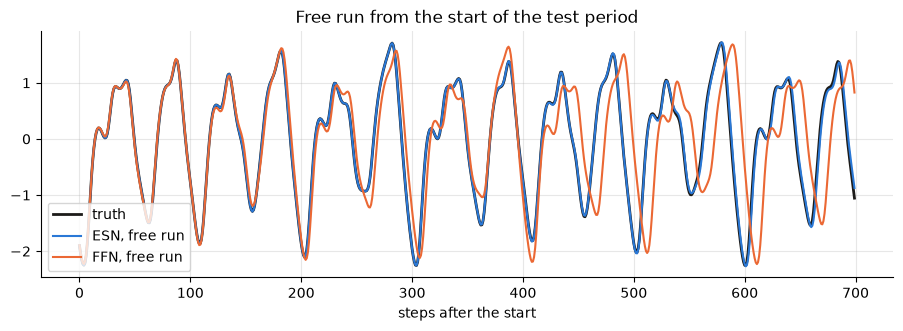

,seed,ESN_valid_steps,FFN_valid_steps
0,1,606,186
1,2,448,186
2,3,605,100


In [11]:
def valid_steps(truth, pred, thr=0.2):
    e = np.abs(truth - pred) / truth.std()
    bad = ~(e <= thr)
    return int(np.argmax(bad)) if bad.any() else len(e)

def esn_free(seed, steps=1000):
    esn = ESN(300, 1.0, 0.5, 0.5, 0.2, seed=seed)
    X = esn.run(z[:VAL_END]); F = esn.features(z[:VAL_END], X)
    G = slice(50, TRAIN_END - 1)
    def run(B, start, n):
        x, y, out = X[start].copy(), F[start] @ B, []
        for _ in range(n):
            out.append(y[0]); x = esn.step(x, y[0]); y = np.concatenate([[1, y[0]], x]) @ B
        return np.array(out)
    best = max(((ridge(F[G], z[51:TRAIN_END, None], lam), lam) for lam in LAMBDAS),
               key=lambda Bl: valid_steps(z[TRAIN_END:VAL_END], run(Bl[0], TRAIN_END - 1, VAL_END - TRAIN_END)))
    return run(best[0], VAL_END - 1, steps)

def ffn_free(seed, steps=1000, L=20):
    T1 = task(z, 1); X = windows(z, L, T1["n"])
    net, _ = train_mlp(X, T1["Y"], T1["train"], T1["val"], seed=seed)
    win, out = list(z[VAL_END - L:VAL_END][::-1]), []
    for _ in range(steps):
        y = net.predict(np.array(win[:L])[None])[0, 0]; out.append(y); win.insert(0, y)
    return np.array(out)

truth = z[VAL_END:VAL_END + 1000]
rows = []
for seed in [1, 2, 3]:
    pe, pf = esn_free(seed), ffn_free(seed)
    rows.append(dict(seed=seed, ESN_valid_steps=valid_steps(truth, pe), FFN_valid_steps=valid_steps(truth, pf)))
    if seed == 1:
        fig, ax = plt.subplots()
        ax.plot(truth[:700], color=COL["truth"], lw=2, label="truth")
        ax.plot(pe[:700], color=COL["esn"], label="ESN, free run"); ax.plot(pf[:700], color=COL["ffn"], label="FFN, free run")
        ax.set(title="Free run from the start of the test period", xlabel="steps after the start"); ax.legend(); plt.show()
pd.DataFrame(rows)

## 6 · NG-RC: the reservoir without the reservoir

Next-generation RC (Gauthier et al., 2021): the features are a constant, $k$ delayed copies of the state and their unique quadratic monomials; the
readout predicts the step $v(t+1) - v(t)$. On Lorenz-63 with $k = 2$ that is $1 + 6 + 21 = 28$ features.

The data is standardized first. Without it, a ridge penalty of $2.5\cdot10^{-6}$ is negligible next to quadratic features of size $\sim 10^3$, the
problem is effectively unregularized (condition number $\sim 10^{18}$), and the free run blows up within a few steps.

In [12]:
DT, LT_STEPS = 0.025, 1 / 0.9056 / 0.025          # ≈ 44 steps per Lyapunov time
WARM, STARTS, GAP, TEST = 200, 5, 250, 600
V = lorenz(WARM + 4000 + GAP * (STARTS - 1) + 2400)

def lorenz_valid(truth, pred, thr=0.4):
    e = np.sqrt(np.sum((truth - pred) ** 2, 1) / np.mean(np.sum((truth - truth.mean(0)) ** 2, 1)))
    bad = ~(e <= thr)
    return (int(np.argmax(bad)) if bad.any() else len(e)) / LT_STEPS

def ngrc(ntr, k=2, quad=True, lam=2.5e-7):
    ts = WARM + ntr
    m, s = V[:ts].mean(0), V[:ts].std(0); Z = (V - m) / s
    combos = list(combinations_with_replacement(range(3 * k), 2)) if quad else []
    feat = lambda lin: np.concatenate([[1.0], lin, [lin[i] * lin[j] for i, j in combos]])
    lin_at = lambda Zs, t: np.concatenate([Zs[t - j] for j in range(k)])
    F = np.array([feat(lin_at(Z, t)) for t in range(WARM, ts - 1)])     # last target v(ts − 1), as for the ESN
    B = ridge(F, Z[WARM + 1:ts] - Z[WARM:ts - 1], lam)
    valids = []
    with np.errstate(all="ignore"):
        for t0 in ts + GAP * np.arange(STARTS):
            hist = list(Z[t0 - k:t0])
            for _ in range(TEST):
                hist.append(hist[-1] + feat(np.concatenate([hist[-1 - j] for j in range(k)])) @ B)
            valids.append(lorenz_valid(V[t0:t0 + TEST], np.array(hist[k:]) * s + m))
    return np.mean(valids)

def esn_lorenz(ntr, seed=1, lam=1e-9):
    ts = WARM + ntr; last = ts + GAP * (STARTS - 1)
    m, s = V[:ts].mean(0), V[:ts].std(0); Z = (V - m) / s
    esn = ESN(300, 0.9, 0.5, 0.5, bias=0.5, n_in=3, seed=seed)
    X = esn.run(Z[:last]); F = esn.features(Z[:last], X)
    B = ridge(F[WARM:ts - 1], Z[WARM + 1:ts], lam)
    valids = []
    with np.errstate(all="ignore"):
        for t0 in ts + GAP * np.arange(STARTS):
            x, y, out = X[t0 - 1].copy(), F[t0 - 1] @ B, []
            for _ in range(TEST):
                out.append(y); x = esn.step(x, np.clip(y, -50, 50)); y = np.concatenate([[1], y, x]) @ B
            valids.append(lorenz_valid(V[t0:t0 + TEST], np.array(out) * s + m))
    return np.mean(valids)

pd.DataFrame([dict(training_points=n, NGRC_valid_LT=round(ngrc(n), 2), ESN_valid_LT=round(esn_lorenz(n), 2)) for n in [100, 200, 400, 1000, 4000]])

,training_points,NGRC_valid_LT,ESN_valid_LT
0,100,3.07,1.25
1,200,4.05,1.36
2,400,4.12,2.88
3,1000,4.57,4.08
4,4000,5.23,6.40


NG-RC is far more data-efficient (and needs one warm-up point instead of a 200-step washout); with 1,000 points or more the ESN catches up.
Two ablations show where NG-RC's skill comes from:

In [13]:
pd.DataFrame([dict(k=k, quadratic=q, valid_LT=round(ngrc(400, k=k, quad=q), 2)) for q in [True, False] for k in [1, 2, 3]])

,k,quadratic,valid_LT
0,1,True,1.16
1,2,True,4.12
2,3,True,3.91
3,1,False,0.05
4,2,False,0.09
5,3,False,0.10


Without the quadratic terms the forecast fails almost at once; with $k = 1$ (no delay) the model is like a single Euler step.

## 7 · Takeaways

| | FFN (backprop) | ESN (reservoir) | NG-RC |
|---|---|---|---|
| Memory | the window $L$ you choose | fading, set by $\rho$, $\alpha$, $N$ | $k$ delay taps |
| Training | iterative, non-convex, seed-dependent | one ridge solve | one ridge solve |
| Shines on | complex real data, large datasets | dynamical signals, small data, physical hardware | low-dimensional smooth dynamics, very little data |
| Fails when | the window is too short | the echo state property is lost | many variables (feature explosion) |

**Next:** the other notebooks in this folder (`01`–`09`) go deeper into single topics; see the repository README for the learning path.